# 6 · Deep portfolios: autoencoders vs PCA for index tracking
An **autoencoder** is a neural network trained to reproduce its input through a narrow bottleneck. Applied to stock returns, the bottleneck learns a few common factors. Stocks that the network reconstructs well are "communal": they move with the market's common structure. Heaton, Polson & Witte (2017) proposed building index-tracking portfolios from the most communal stocks.

This notebook tests that idea on 40 US large caps (2013-2026):
1. Does a sparse non-linear autoencoder capture the cross-section better than linear PCA, in and out of sample?
2. Do tracking portfolios built from the most communal stocks track SPY better out of sample than portfolios built from PCA rankings, from the *least* communal stocks, or from random picks?

Training period: 2013-2020. Test period: 2021-October 2026, never seen during fitting.

In [1]:
import sys, pathlib, os, warnings
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from scipy.optimize import nnls
from sklearn.decomposition import PCA
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); DATA = pathlib.Path("../data")
px = pd.read_csv(DATA / "large_caps_2013.csv", index_col=0, parse_dates=True)
ret = np.log(px).diff().dropna()
spy = ret.pop("SPY")
tr, te = ret[:"2020"], ret["2021":]
mu, sd = tr.mean(), tr.std()
Ztr, Zte = ((tr - mu) / sd).to_numpy("float32"), ((te - mu) / sd).to_numpy("float32")
print(f"{ret.shape[1]} stocks; train {len(tr):,} trading days ({tr.index[0]:%Y}-{tr.index[-1]:%Y}), test {len(te):,} trading days ({te.index[0]:%Y}-{te.index[-1]:%b %Y})")

40 stocks; train 2,014 trading days (2013-2020), test 1,464 trading days (2021-Oct 2026)


## 1. Reconstruction: autoencoder vs PCA
Both compress 40 standardised return series into **5 factors**. The autoencoder has one hidden layer of 5 units with a sigmoid-free (ELU) activation and an L1 penalty on the codes to keep them sparse, and a linear decoder. It is trained with early stopping on the last 20% of the training period. Results are averaged over 5 random initialisations.

In [2]:
K = 5
def autoencoder(seed):
    tf.keras.utils.set_random_seed(seed)
    inp = tf.keras.Input((Ztr.shape[1],))
    code = tf.keras.layers.Dense(K, activation="elu", activity_regularizer=tf.keras.regularizers.l1(1e-4))(inp)
    out = tf.keras.layers.Dense(Ztr.shape[1])(code)
    m = tf.keras.Model(inp, out); m.compile(tf.keras.optimizers.Adam(1e-3), "mse")
    m.fit(Ztr, Ztr, epochs=300, batch_size=64, validation_split=0.2, verbose=0,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
    return m
aes = [autoencoder(s) for s in range(5)]
pca = PCA(K).fit(Ztr)
def r2(Z, Zhat): return 1 - ((Z - Zhat) ** 2).sum() / (Z ** 2).sum()
rec = {"PCA (5 components)": (pca.inverse_transform(pca.transform(Ztr)), pca.inverse_transform(pca.transform(Zte)))}
ae_tr = np.mean([m.predict(Ztr, verbose=0) for m in aes], axis=0); ae_te = np.mean([m.predict(Zte, verbose=0) for m in aes], axis=0)
rec["autoencoder (5 codes, 5-seed average)"] = (ae_tr, ae_te)
single = [r2(Zte, m.predict(Zte, verbose=0)) for m in aes]
tab = pd.DataFrame({n: {"variance explained, train %": 100 * r2(Ztr, a), "variance explained, test %": 100 * r2(Zte, b)} for n, (a, b) in rec.items()}).T
print("single autoencoders, test %:", np.round(100 * np.array(single), 1))
tab.round(1)

single autoencoders, test %: [43.5 44.3 43.9 44.1 43.8]


,"variance explained, train %","variance explained, test %"
PCA (5 components),62.0,45.1
"autoencoder (5 codes, 5-seed average)",60.2,45.4


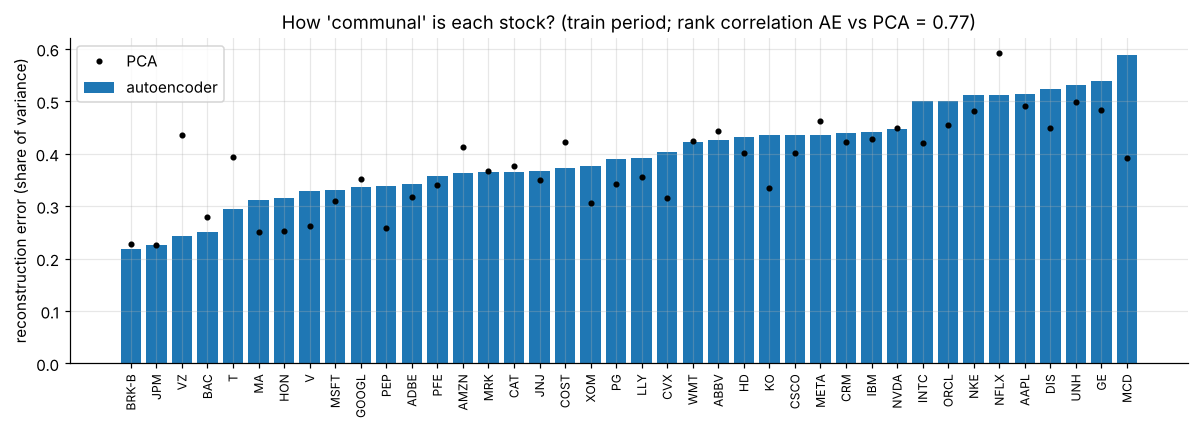

most communal (autoencoder): ['BRK-B', 'JPM', 'VZ', 'BAC', 'T', 'MA', 'HON', 'V', 'MSFT', 'GOOGL']
least communal: ['ORCL', 'NKE', 'NFLX', 'AAPL', 'DIS', 'UNH', 'GE', 'MCD']


In [3]:
err = pd.DataFrame({"PCA": ((Ztr - rec["PCA (5 components)"][0]) ** 2).mean(0), "autoencoder": ((Ztr - ae_tr) ** 2).mean(0)}, index=tr.columns)
rank_corr = err.rank().corr(method="spearman").iloc[0, 1]
fig, ax = plt.subplots(figsize=(11, 4))
o = err["autoencoder"].sort_values().index
ax.bar(range(len(o)), err.loc[o, "autoencoder"], label="autoencoder"); ax.plot(range(len(o)), err.loc[o, "PCA"], "k.", label="PCA")
ax.set_xticks(range(len(o)), o, rotation=90, fontsize=8); ax.set_ylabel("reconstruction error (share of variance)")
ax.set_title(f"How 'communal' is each stock? (train period; rank correlation AE vs PCA = {rank_corr:.2f})"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "autoencoder_communality.png", bbox_inches="tight"); plt.show()
print("most communal (autoencoder):", list(o[:10])); print("least communal:", list(o[-8:]))

## 2. Tracking SPY with a few stocks
For k = 5, 10, 15 and 20 stocks, choose the names by each ranking. Weights are non-negative least squares of SPY's daily returns on those stocks over the training period, then frozen. The tracking error (annualised s.d. of portfolio minus SPY returns) is measured in the test period. Random selection is repeated 200 times.

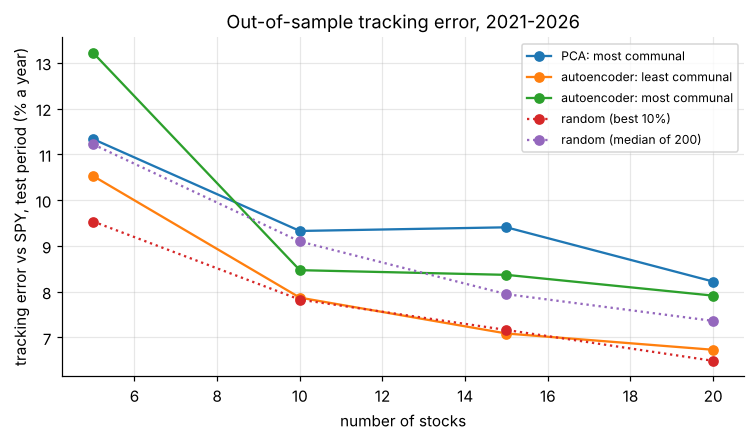

k,5,10,15,20
selection,,,,
PCA: most communal,11.33,9.33,9.41,8.22
autoencoder: least communal,10.53,7.87,7.09,6.73
autoencoder: most communal,13.22,8.47,8.37,7.91
random (best 10%),9.53,7.83,7.16,6.49
random (median of 200),11.22,9.10,7.95,7.36


In [4]:
def te_of(names):
    w, _ = nnls(tr[names].to_numpy(), spy[tr.index].to_numpy())
    d_tr = tr[names].to_numpy() @ w - spy[tr.index].to_numpy(); d_te = te[names].to_numpy() @ w - spy[te.index].to_numpy()
    return 100 * d_tr.std() * np.sqrt(252), 100 * d_te.std() * np.sqrt(252), w.sum()
rng = np.random.default_rng(0); rows = []
for k in [5, 10, 15, 20]:
    picks = {"autoencoder: most communal": list(err["autoencoder"].sort_values().index[:k]),
             "PCA: most communal": list(err["PCA"].sort_values().index[:k]),
             "autoencoder: least communal": list(err["autoencoder"].sort_values().index[-k:])}
    for n, names in picks.items():
        a, b, s = te_of(names); rows.append({"k": k, "selection": n, "tracking error train %": a, "tracking error test %": b, "sum of weights": s})
    rnd = np.array([te_of(list(rng.choice(tr.columns, k, replace=False)))[:2] for _ in range(200)])
    rows.append({"k": k, "selection": "random (median of 200)", "tracking error train %": np.median(rnd[:, 0]), "tracking error test %": np.median(rnd[:, 1]), "sum of weights": np.nan})
    rows.append({"k": k, "selection": "random (best 10%)", "tracking error train %": np.percentile(rnd[:, 0], 10), "tracking error test %": np.percentile(rnd[:, 1], 10), "sum of weights": np.nan})
trk = pd.DataFrame(rows)
piv = trk.pivot(index="selection", columns="k", values="tracking error test %")
fig, ax = plt.subplots(figsize=(8, 4))
for n in piv.index: ax.plot(piv.columns, piv.loc[n], "o-", label=n, ls=":" if "random" in n else "-")
ax.set_xlabel("number of stocks"); ax.set_ylabel("tracking error vs SPY, test period (% a year)"); ax.set_title("Out-of-sample tracking error, 2021-2026"); ax.legend(fontsize=8)
plt.savefig(IMG / "autoencoder_tracking.png", bbox_inches="tight"); plt.show()
piv.round(2)

## Findings
* **The autoencoder learns essentially what PCA learns.** With 5 factors, PCA explains 62.0% of the variance of 40 standardised daily return series in 2013-2020 and the autoencoder 60.2%. Out of sample (2021-2026) they explain 45.1% and 45.4%, and each single autoencoder lands at 43.5-44.3%. The two rank the stocks' "communality" similarly (rank correlation 0.77). At daily frequency the common structure in large-cap returns is close to linear, so the non-linear network adds almost nothing.
* **Both models lose a quarter of their explanatory power out of sample** (62% to 45%). Sector and style factor structure shifted after 2020 (rates, energy, AI-related tech), which is the more important practical lesson for factor-based tracking.
* **The "most communal stocks" rule does not track SPY better.** With 10 stocks, the autoencoder's most communal names track with a 2021-2026 tracking error of 8.5% a year. PCA's give 9.3% and a random 10-stock basket 9.1% (median of 200). The *least* communal names do better (7.9%), and with 20 stocks they reach 6.7% against 7.4% for random picks.
* **Why:** communality measures how well a stock fits the equal-weighted, standardised factor structure. The most communal names are financials and telecoms (BRK-B, JPM, BAC, VZ, T), while SPY is cap-weighted and dominated by mega-cap technology (AAPL, NVDA, MSFT), which have large stock-specific moves and so look "non-communal". For index tracking, choosing stocks by index weight or by a direct tracking objective (see the LASSO tracker in the `ml-finance-models` repository) is the better route.
* **Note:** "random, best 10%" is chosen with hindsight on the test period and is shown only as a range, not as a usable strategy.